In [ ]:
import os, sys, torch, numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from tqdm import tqdm

sys.path.insert(0, os.getcwd())
from joint_embedding_learning.utils.utils import get_config_details
from joint_embedding_learning.utils.models_setup import get_trained_model
from joint_embedding_learning.data.datasets import get_all_contrastive_datasets

device = "cuda:0"
dataset_name = "dataset_cross_modal"
model_name = "cross_modal"
run_name = "dataset_cross_modal_run_20260408_223408_B64"

# ===== 1. 모델 & 데이터 로드 =====
dataset_config = os.path.join("config", "datasets_config.yaml")
model_config = os.path.join("config", "models_config.yaml")
dataset_details = get_config_details(dataset_config, dataset_name)
model_details = get_config_details(model_config, model_name)

model = get_trained_model(model_name, model_details, dataset_details["dataset_type"], run_name, device)
model.eval()

train_datasets, val_datasets, _ = get_all_contrastive_datasets(dataset_name, data_split="test", device="cpu")
from torch.utils.data import ConcatDataset, DataLoader

train_set = ConcatDataset(train_datasets)
val_set = ConcatDataset(val_datasets)
train_loader = DataLoader(train_set, batch_size=256, shuffle=False, drop_last=False)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False, drop_last=False)

print(f"Train: {len(train_set)}, Val: {len(val_set)}")
print(f"Model loaded from: checkpoints/cross_modal/cross_modal/{run_name}/model.pt")

/home/junsung/anaconda3/envs/cttp_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/junsung/anaconda3/envs/cttp_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/home/junsung/CTTP/joint_embedding_learning/utils/models_setup.py:100: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release,

Train: 6550, Val: 1184
Model loaded from: checkpoints/cross_modal/cross_modal/dataset_cross_modal_run_20260408_224726_B32/model.pt


In [34]:
# ===== 2. 임베딩 추출 =====
def extract_cross_modal_embeddings(loader, model, device):
    """Extract h_i, h_j, z_i, z_j from CrossModalCLR for all data."""
    all_h_i, all_h_j, all_z_i, all_z_j = [], [], [], []
    with torch.no_grad():
        for (x_i, x_j), _ in tqdm(loader, desc="Extracting"):
            x_i = x_i.to(device)
            x_j = x_j.to(device)
            h_i, h_j, z_i, z_j = model(x_i, x_j)
            all_h_i.append(h_i.cpu())
            all_h_j.append(h_j.cpu())
            all_z_i.append(z_i.cpu())
            all_z_j.append(z_j.cpu())
    return (torch.cat(all_h_i), torch.cat(all_h_j),
            torch.cat(all_z_i), torch.cat(all_z_j))

train_h_i, train_h_j, train_z_i, train_z_j = extract_cross_modal_embeddings(train_loader, model, device)
val_h_i, val_h_j, val_z_i, val_z_j = extract_cross_modal_embeddings(val_loader, model, device)

print(f"Train — h_i: {train_h_i.shape}, h_j: {train_h_j.shape}, z_i: {train_z_i.shape}, z_j: {train_z_j.shape}")
print(f"Val   — h_i: {val_h_i.shape}, h_j: {val_h_j.shape}, z_i: {val_z_i.shape}, z_j: {val_z_j.shape}")

Extracting:   0%|          | 0/26 [00:00<?, ?it/s]/home/junsung/CTTP/joint_embedding_learning/data/datasets.py:210: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  daimon_data

Train — h_i: torch.Size([6550, 512]), h_j: torch.Size([6550, 512]), z_i: torch.Size([6550, 64]), z_j: torch.Size([6550, 64])
Val   — h_i: torch.Size([1184, 512]), h_j: torch.Size([1184, 512]), z_i: torch.Size([1184, 64]), z_j: torch.Size([1184, 64])


Running t-SNE on 13100 points (6550 per modality)...


/tmp/ipykernel_1231372/4199758426.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(np.unique(episode_ids[idx])))


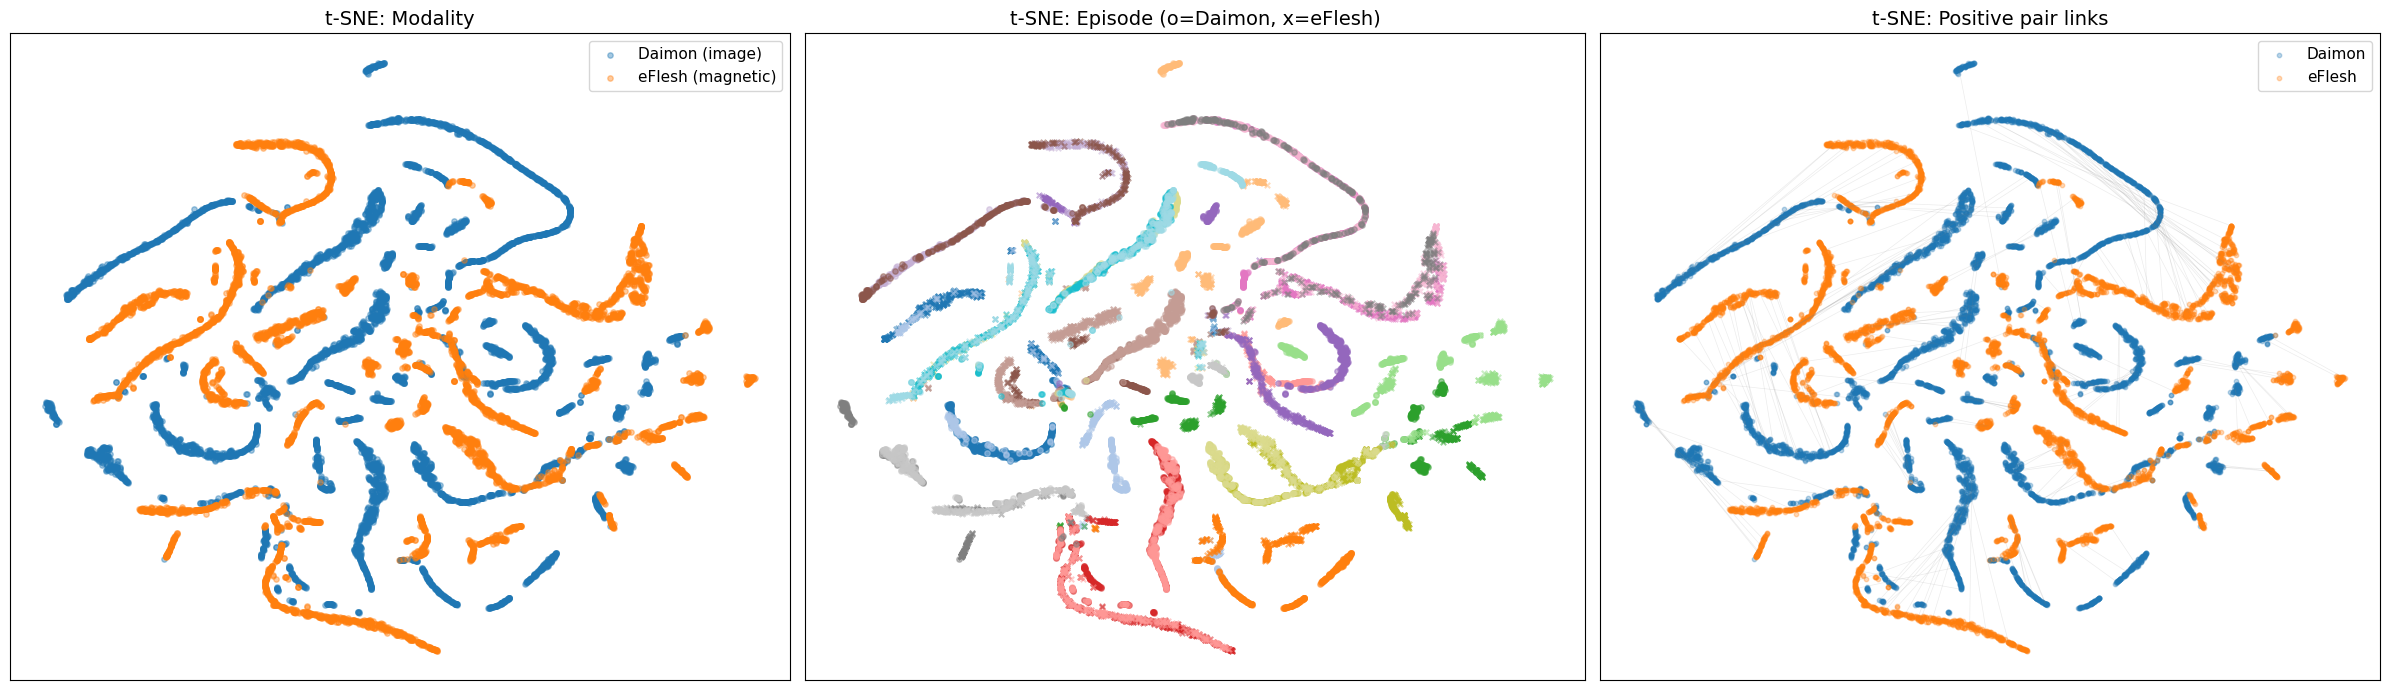

Saved: tsne_cross_modal_train.png


In [35]:
# ===== 3. t-SNE 시각화 (projection space z) =====
# train set으로 시각화 (데이터 적어서 빠름)
N_vis = len(train_z_i)
idx = np.arange(len(train_z_i))

z_i_np = F.normalize(train_z_i[idx], dim=1).numpy()
z_j_np = F.normalize(train_z_j[idx], dim=1).numpy()

combined = np.concatenate([z_i_np, z_j_np], axis=0)  # (2N, 64)
modality_labels = np.array(["Daimon"] * N_vis + ["eFlesh"] * N_vis)

# 에피소드 라벨 복원 (파일 이름에서)
episode_ids = []
for ds in train_datasets:
    if hasattr(ds, 'dataset'):
        base_ds = ds.dataset
    else:
        base_ds = ds
    for f in base_ds.daimon_files:
        ep = int(os.path.basename(f).split("_")[0].replace("ep", ""))
        episode_ids.append(ep)
episode_ids = np.array(episode_ids)
ep_labels = np.concatenate([episode_ids[idx], episode_ids[idx]])

print(f"Running t-SNE on {combined.shape[0]} points ({N_vis} per modality)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
tsne_2d = tsne.fit_transform(combined)

tsne_daimon = tsne_2d[:N_vis]
tsne_eflesh = tsne_2d[N_vis:]

# --- Plot 1: 모달리티별 색상 ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

ax = axes[0]
ax.scatter(tsne_daimon[:, 0], tsne_daimon[:, 1], c="tab:blue", alpha=0.4, s=15, label="Daimon (image)")
ax.scatter(tsne_eflesh[:, 0], tsne_eflesh[:, 1], c="tab:orange", alpha=0.4, s=15, label="eFlesh (magnetic)")
ax.set_title("t-SNE: Modality", fontsize=14)
ax.legend(fontsize=11)
ax.set_xticks([]); ax.set_yticks([])

# --- Plot 2: 에피소드별 색상 ---
ax = axes[1]
unique_eps = np.unique(ep_labels)
cmap = plt.cm.get_cmap("tab20", len(np.unique(episode_ids[idx])))
for i, ep in enumerate(np.unique(episode_ids[idx])):
    mask_d = episode_ids[idx] == ep
    mask_e = episode_ids[idx] == ep
    ax.scatter(tsne_daimon[mask_d, 0], tsne_daimon[mask_d, 1], c=[cmap(i)], alpha=0.5, s=15, marker="o")
    ax.scatter(tsne_eflesh[mask_e, 0], tsne_eflesh[mask_e, 1], c=[cmap(i)], alpha=0.5, s=15, marker="x")
ax.set_title("t-SNE: Episode (o=Daimon, x=eFlesh)", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])

# --- Plot 3: Positive pair 연결선 ---
ax = axes[2]
ax.scatter(tsne_daimon[:, 0], tsne_daimon[:, 1], c="tab:blue", alpha=0.3, s=10, label="Daimon")
ax.scatter(tsne_eflesh[:, 0], tsne_eflesh[:, 1], c="tab:orange", alpha=0.3, s=10, label="eFlesh")
sample_pairs = np.random.RandomState(0).choice(N_vis, size=min(200, N_vis), replace=False)
for k in sample_pairs:
    ax.plot([tsne_daimon[k, 0], tsne_eflesh[k, 0]],
            [tsne_daimon[k, 1], tsne_eflesh[k, 1]], c="gray", alpha=0.15, linewidth=0.5)
ax.set_title("t-SNE: Positive pair links", fontsize=14)
ax.legend(fontsize=11)
ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig("tsne_cross_modal_train.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: tsne_cross_modal_train.png")

Running t-SNE on 2368 points (1184 per modality)...


/tmp/ipykernel_1231372/2927075485.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", len(np.unique(episode_ids[idx])))


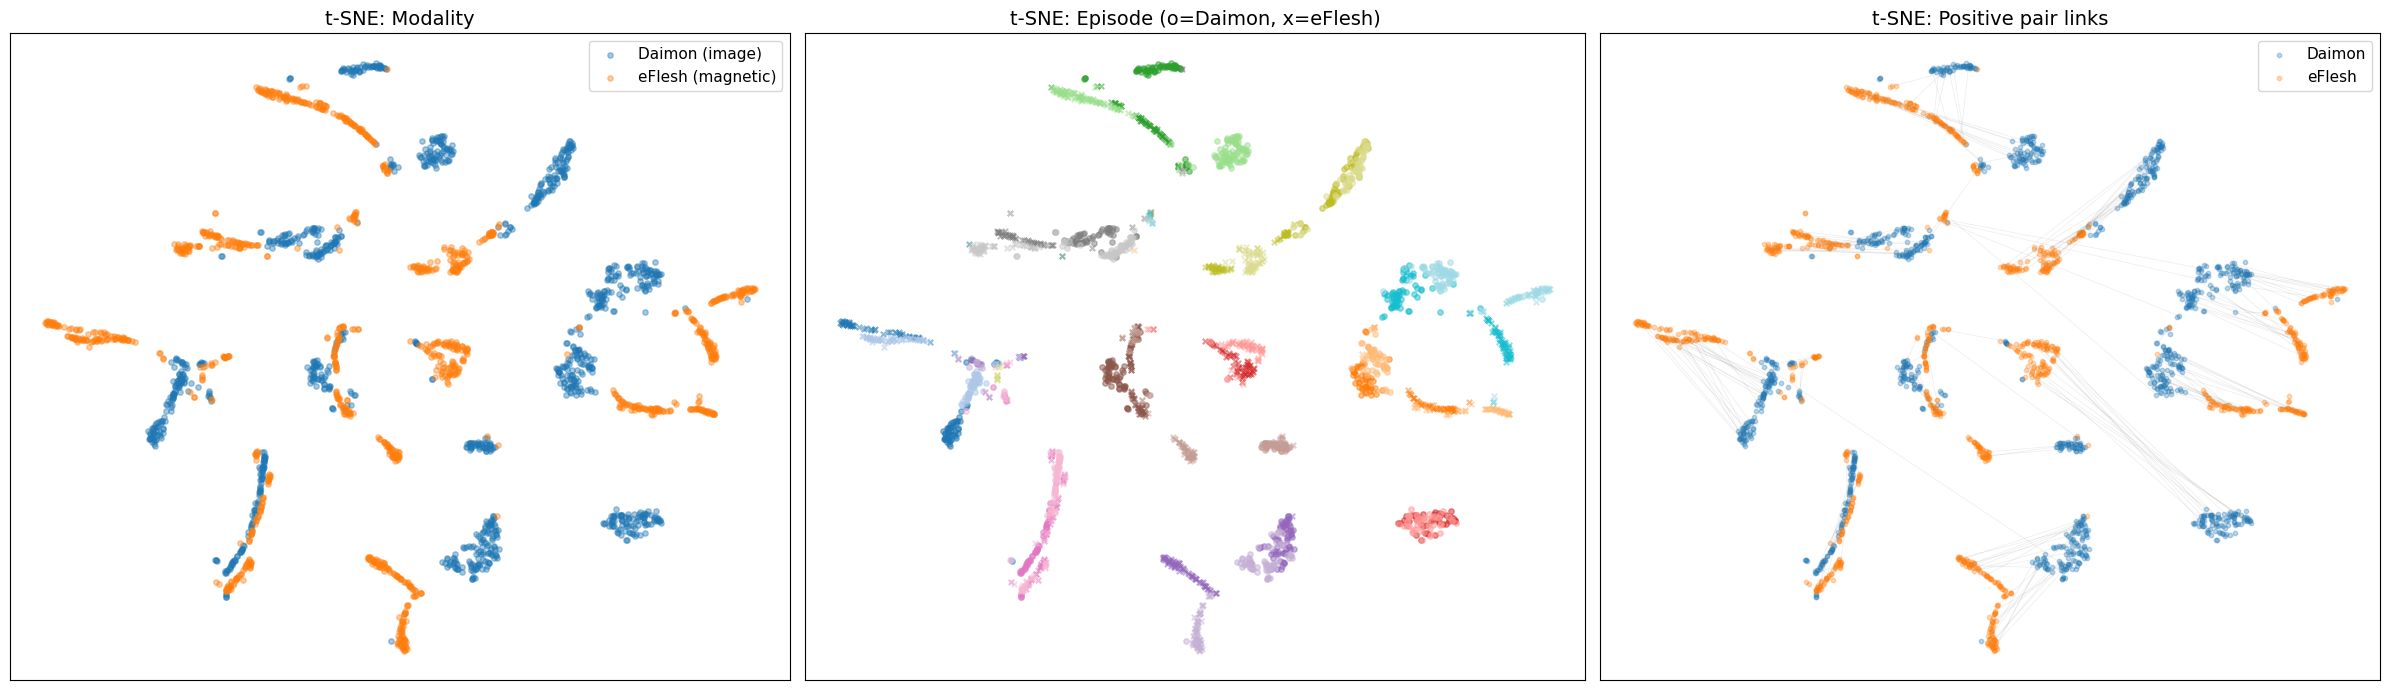

Saved: tsne_cross_modal_val.png


In [29]:
# ===== 3. t-SNE 시각화 (projection space z) =====
# Val set으로 시각화 (데이터 적어서 빠름)
N_vis = len(val_z_i)
idx = np.arange(len(val_z_i))

z_i_np = F.normalize(val_z_i[idx], dim=1).numpy()
z_j_np = F.normalize(val_z_j[idx], dim=1).numpy()

combined = np.concatenate([z_i_np, z_j_np], axis=0)  # (2N, 64)
modality_labels = np.array(["Daimon"] * N_vis + ["eFlesh"] * N_vis)

# 에피소드 라벨 복원 (파일 이름에서)
episode_ids = []
for ds in val_datasets:
    if hasattr(ds, 'dataset'):
        base_ds = ds.dataset
    else:
        base_ds = ds
    for f in base_ds.daimon_files:
        ep = int(os.path.basename(f).split("_")[0].replace("ep", ""))
        episode_ids.append(ep)
episode_ids = np.array(episode_ids)
ep_labels = np.concatenate([episode_ids[idx], episode_ids[idx]])

print(f"Running t-SNE on {combined.shape[0]} points ({N_vis} per modality)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
tsne_2d = tsne.fit_transform(combined)

tsne_daimon = tsne_2d[:N_vis]
tsne_eflesh = tsne_2d[N_vis:]

# --- Plot 1: 모달리티별 색상 ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

ax = axes[0]
ax.scatter(tsne_daimon[:, 0], tsne_daimon[:, 1], c="tab:blue", alpha=0.4, s=15, label="Daimon (image)")
ax.scatter(tsne_eflesh[:, 0], tsne_eflesh[:, 1], c="tab:orange", alpha=0.4, s=15, label="eFlesh (magnetic)")
ax.set_title("t-SNE: Modality", fontsize=14)
ax.legend(fontsize=11)
ax.set_xticks([]); ax.set_yticks([])

# --- Plot 2: 에피소드별 색상 ---
ax = axes[1]
unique_eps = np.unique(ep_labels)
cmap = plt.cm.get_cmap("tab20", len(np.unique(episode_ids[idx])))
for i, ep in enumerate(np.unique(episode_ids[idx])):
    mask_d = episode_ids[idx] == ep
    mask_e = episode_ids[idx] == ep
    ax.scatter(tsne_daimon[mask_d, 0], tsne_daimon[mask_d, 1], c=[cmap(i)], alpha=0.5, s=15, marker="o")
    ax.scatter(tsne_eflesh[mask_e, 0], tsne_eflesh[mask_e, 1], c=[cmap(i)], alpha=0.5, s=15, marker="x")
ax.set_title("t-SNE: Episode (o=Daimon, x=eFlesh)", fontsize=14)
ax.set_xticks([]); ax.set_yticks([])

# --- Plot 3: Positive pair 연결선 ---
ax = axes[2]
ax.scatter(tsne_daimon[:, 0], tsne_daimon[:, 1], c="tab:blue", alpha=0.3, s=10, label="Daimon")
ax.scatter(tsne_eflesh[:, 0], tsne_eflesh[:, 1], c="tab:orange", alpha=0.3, s=10, label="eFlesh")
sample_pairs = np.random.RandomState(0).choice(N_vis, size=min(200, N_vis), replace=False)
for k in sample_pairs:
    ax.plot([tsne_daimon[k, 0], tsne_eflesh[k, 0]],
            [tsne_daimon[k, 1], tsne_eflesh[k, 1]], c="gray", alpha=0.15, linewidth=0.5)
ax.set_title("t-SNE: Positive pair links", fontsize=14)
ax.legend(fontsize=11)
ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig("tsne_cross_modal_val.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: tsne_cross_modal_val.png")

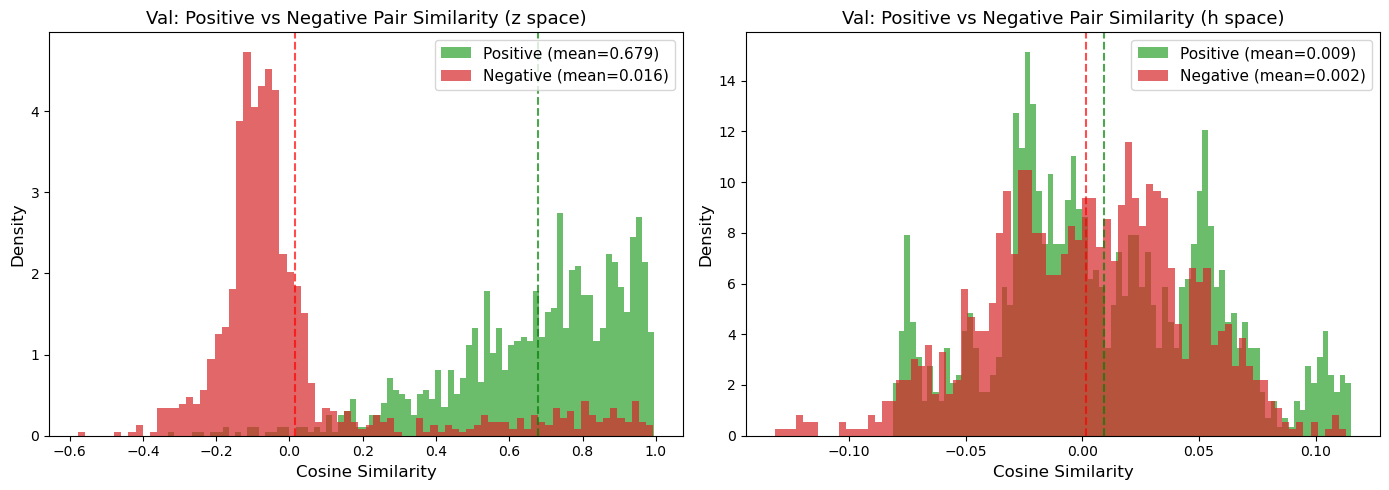

Saved: cosine_similarity_cross_modal.png

[z space] Pos mean: 0.6790 | Neg mean: 0.0159 | Gap: 0.6630
[h space] Pos mean: 0.0092 | Neg mean: 0.0017 | Gap: 0.0076


In [31]:
# ===== 4. 코사인 유사도 분석 =====
z_i_norm = F.normalize(val_z_i, dim=1)
z_j_norm = F.normalize(val_z_j, dim=1)

# Positive: 같은 인덱스 pair
pos_sim = (z_i_norm * z_j_norm).sum(dim=1).numpy()

# Negative: 랜덤 셔플 pair
perm = np.random.RandomState(0).permutation(len(z_j_norm))
neg_sim = (z_i_norm * z_j_norm[perm]).sum(dim=1).numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(pos_sim, bins=80, alpha=0.7, label=f"Positive (mean={pos_sim.mean():.3f})", color="tab:green", density=True)
ax.hist(neg_sim, bins=80, alpha=0.7, label=f"Negative (mean={neg_sim.mean():.3f})", color="tab:red", density=True)
ax.set_xlabel("Cosine Similarity", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.set_title("Val: Positive vs Negative Pair Similarity (z space)", fontsize=13)
ax.legend(fontsize=11)
ax.axvline(x=pos_sim.mean(), color="green", linestyle="--", alpha=0.7)
ax.axvline(x=neg_sim.mean(), color="red", linestyle="--", alpha=0.7)

# Representation space (h) 에서도
h_i_norm = F.normalize(val_h_i, dim=1)
h_j_norm = F.normalize(val_h_j, dim=1)
pos_sim_h = (h_i_norm * h_j_norm).sum(dim=1).numpy()
neg_sim_h = (h_i_norm * h_j_norm[perm]).sum(dim=1).numpy()

ax = axes[1]
ax.hist(pos_sim_h, bins=80, alpha=0.7, label=f"Positive (mean={pos_sim_h.mean():.3f})", color="tab:green", density=True)
ax.hist(neg_sim_h, bins=80, alpha=0.7, label=f"Negative (mean={neg_sim_h.mean():.3f})", color="tab:red", density=True)
ax.set_xlabel("Cosine Similarity", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.set_title("Val: Positive vs Negative Pair Similarity (h space)", fontsize=13)
ax.legend(fontsize=11)
ax.axvline(x=pos_sim_h.mean(), color="green", linestyle="--", alpha=0.7)
ax.axvline(x=neg_sim_h.mean(), color="red", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("cosine_similarity_cross_modal.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: cosine_similarity_cross_modal.png")
print(f"\n[z space] Pos mean: {pos_sim.mean():.4f} | Neg mean: {neg_sim.mean():.4f} | Gap: {pos_sim.mean() - neg_sim.mean():.4f}")
print(f"[h space] Pos mean: {pos_sim_h.mean():.4f} | Neg mean: {neg_sim_h.mean():.4f} | Gap: {pos_sim_h.mean() - neg_sim_h.mean():.4f}")

In [32]:
# ===== 5. Cross-Modal Retrieval Accuracy =====
def retrieval_accuracy(z_query, z_gallery, ks=[1, 5, 10]):
    """Daimon query → eFlesh gallery (또는 반대). Top-k retrieval accuracy."""
    z_q = F.normalize(z_query, dim=1)
    z_g = F.normalize(z_gallery, dim=1)
    sim = z_q @ z_g.T  # (N, N)
    results = {}
    for k in ks:
        topk_idx = sim.topk(k, dim=1).indices  # (N, k)
        correct = (topk_idx == torch.arange(len(z_q)).unsqueeze(1)).any(dim=1)
        results[k] = correct.float().mean().item()
    return results

# Projection space (z)
print("===== Retrieval Accuracy (z space) =====")
d2e_z = retrieval_accuracy(val_z_i, val_z_j)
e2d_z = retrieval_accuracy(val_z_j, val_z_i)
for k in d2e_z:
    print(f"  Top-{k}: Daimon→eFlesh {d2e_z[k]*100:.1f}% | eFlesh→Daimon {e2d_z[k]*100:.1f}%")

# Representation space (h)
print("\n===== Retrieval Accuracy (h space) =====")
d2e_h = retrieval_accuracy(val_h_i, val_h_j)
e2d_h = retrieval_accuracy(val_h_j, val_h_i)
for k in d2e_h:
    print(f"  Top-{k}: Daimon→eFlesh {d2e_h[k]*100:.1f}% | eFlesh→Daimon {e2d_h[k]*100:.1f}%")

# Train set
print("\n===== Retrieval Accuracy (Train, z space) =====")
d2e_train = retrieval_accuracy(train_z_i, train_z_j)
e2d_train = retrieval_accuracy(train_z_j, train_z_i)
for k in d2e_train:
    print(f"  Top-{k}: Daimon→eFlesh {d2e_train[k]*100:.1f}% | eFlesh→Daimon {e2d_train[k]*100:.1f}%")

print("\n===== Summary =====")
print(f"Val  Retrieval@1 (z): D→E {d2e_z[1]*100:.1f}%, E→D {e2d_z[1]*100:.1f}%")
print(f"Train Retrieval@1 (z): D→E {d2e_train[1]*100:.1f}%, E→D {e2d_train[1]*100:.1f}%")

===== Retrieval Accuracy (z space) =====
  Top-1: Daimon→eFlesh 0.8% | eFlesh→Daimon 0.8%
  Top-5: Daimon→eFlesh 5.0% | eFlesh→Daimon 4.6%
  Top-10: Daimon→eFlesh 9.9% | eFlesh→Daimon 9.4%

===== Retrieval Accuracy (h space) =====
  Top-1: Daimon→eFlesh 0.3% | eFlesh→Daimon 0.3%
  Top-5: Daimon→eFlesh 1.2% | eFlesh→Daimon 0.9%
  Top-10: Daimon→eFlesh 1.5% | eFlesh→Daimon 1.6%

===== Retrieval Accuracy (Train, z space) =====
  Top-1: Daimon→eFlesh 0.4% | eFlesh→Daimon 0.4%
  Top-5: Daimon→eFlesh 2.4% | eFlesh→Daimon 2.3%
  Top-10: Daimon→eFlesh 4.9% | eFlesh→Daimon 4.4%

===== Summary =====
Val  Retrieval@1 (z): D→E 0.8%, E→D 0.8%
Train Retrieval@1 (z): D→E 0.4%, E→D 0.4%
